Grouping the metrics by test set and by mechanistic target

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Configuration ---
root_data_dir = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class" # XGBoost
root_data_dir_tabPFN = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\tabPFN\class" # tabPFN
grouping_file = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\Aeid_Mech_targets.csv"

# --- Load AEID groupings ---
group_df = pd.read_csv(grouping_file)
aeid_to_group = dict(zip(group_df['aeid'], group_df['grouped_mech_target']))
aeid_to_acr = dict(zip(group_df['aeid'], group_df['mech_target_acronym']))

# --- Data collection ---
results = []

for aeid_folder in os.listdir(root_data_dir):
    if not aeid_folder.isdigit():
        continue

    aeid_path = os.path.join(root_data_dir, aeid_folder, "FS_RandomForest")
    if not os.path.isdir(aeid_path):
        continue

    for mode in ['mb_val_srs_neg', 'mb_val_srs_pos', 'mb_val_structure']:
        metrics_file = os.path.join(aeid_path, mode, 'metrics.csv')
        report_file = os.path.join(aeid_path, mode, 'report_default.csv')

        if os.path.exists(metrics_file) and os.path.exists(report_file):
            metrics_df = pd.read_csv(metrics_file)
            report_df = pd.read_csv(report_file, index_col=0)

            if not metrics_df.empty:
                metrics = metrics_df.iloc[0]
            else:
                continue  # skip if no metrics

            if 'True' in report_df.index:
                precision_true = report_df.loc['True', 'precision']
                recall_true = report_df.loc['True', 'recall']
            else:
                precision_true = None
                recall_true = None

            if 'False' in report_df.index:
                recall_false = report_df.loc['False', 'recall']
            else:
                recall_false = None

            results.append({
                'aeid': int(aeid_folder),
                'group': aeid_to_group.get(int(aeid_folder), 'Unknown'),
                'acr': aeid_to_acr.get(int(aeid_folder), 'Unknown'),
                'mode': mode,
                'f1_micro': metrics.get('f1_micro'), # chose metrics I am interested in
                'f1_macro': metrics.get('f1_macro'),
                'balanced_accuracy': metrics.get('balanced_accuracy'),
                'n_pos': metrics.get('n_pos'),
                #'pr_auc': metrics.get('pr_auc')
                'precision': precision_true,
                'Sensitivity': recall_true,
                'Specificity': recall_false,
                'roc_auc': metrics.get('roc_auc')
            })

In [ ]:
df = pd.DataFrame(results)
df = df[df['group'] != 'Unknown']

In [ ]:
### Put the results into a dataframe and group them for visualization with all the mechanistic targets

df_combined = pd.concat([df, df1], ignore_index=True)
df_melted = df_combined.melt(
    id_vars=['aeid', 'acr', 'mode'],
    value_vars=['balanced_accuracy', 'Sensitivity', 'Specificity', 'f1_micro', 'roc_auc'], 
    var_name='metric',
    value_name='value'
)
mode_labels = {
    'mb_val_srs_neg': 'Spectra neg',
    'mb_val_srs_pos': 'Spectra pos',
    'mb_val_structure': 'Structure',
    'MLinvitroTox v2': 'MLinvitroTox v2'
}
df_melted['mode'] = df_melted['mode'].map(mode_labels)

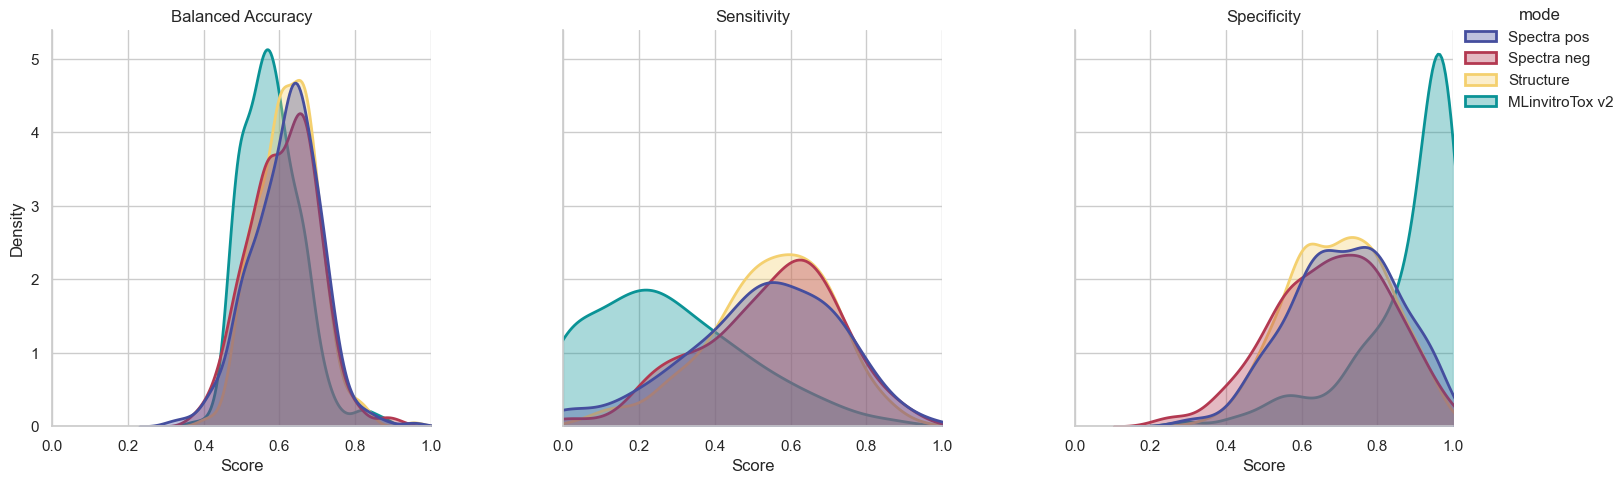

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Keep only metrics of interest
df_plot = df_melted[
    df_melted['metric'].isin(['balanced_accuracy', 'Sensitivity', 'Specificity'])
].copy()

# Prettier labels
metric_labels = {
    'balanced_accuracy': 'Balanced Accuracy',
    'Sensitivity': 'Sensitivity',
    'Specificity': 'Specificity'
}
df_plot['metric'] = df_plot['metric'].map(metric_labels)

palette = {
    'Spectra pos': '#454e9e',
    'Spectra neg': '#b33951',
    'Structure': '#f4d06f',
    'MLinvitroTox v2': '#0a9396'
}
hue_order = list(palette.keys())

# Desired panel order
metric_order = ['Balanced Accuracy', 'Sensitivity', 'Specificity']
title_map = {
    'Balanced Accuracy': 'Balanced Accuracy',
    'Sensitivity': 'Sensitivity',
    'Specificity': 'Specificity'
}

g = sns.displot(
    data=df_plot,
    x='value',
    hue='mode',
    col='metric',
    col_order=metric_order,
    kind='kde',
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=2,
    height=5,
    aspect=1,
    palette=palette,
    hue_order=hue_order
)

# Labels
g.set_axis_labels('Score', 'Density')
g.set(xlim=(0, 1))

for ax, metric in zip(g.axes.flat, metric_order):
    ax.set_title(title_map[metric])

# Space between panels
g.fig.subplots_adjust(wspace=0.35)

# Legend upper right
if g._legend is not None:
    g._legend.set_bbox_to_anchor((0.98, 0.98))
    g._legend._loc = 1

#plt.savefig("density_model_performance_v2_and_v3.svg")
plt.show()

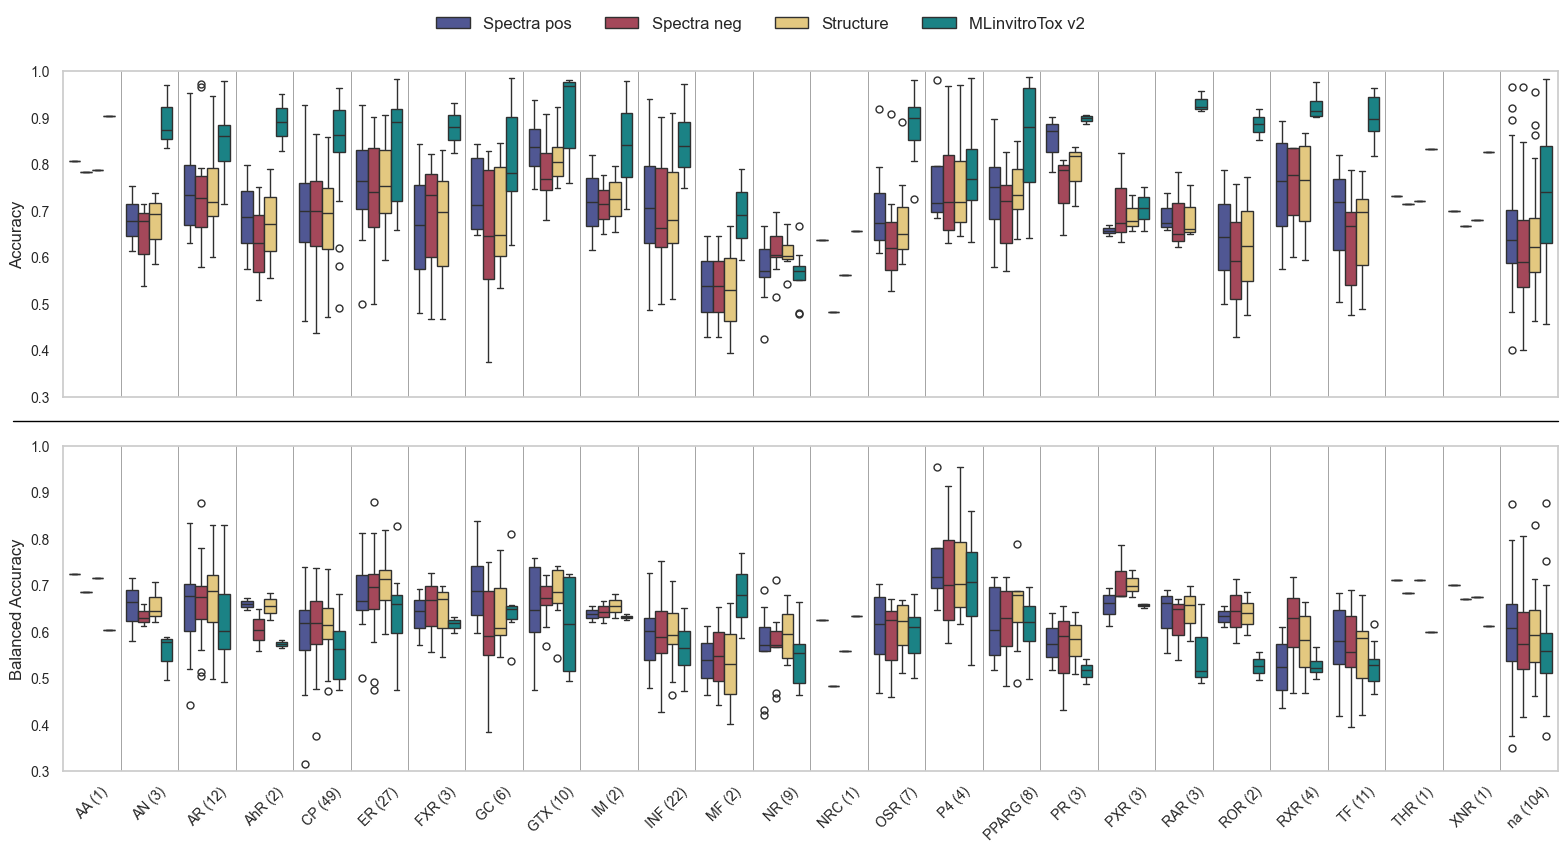

In [6]:
### Visulaize in a boxplot grouped by MT ###

df_melted = df_combined.melt(
    id_vars=['aeid', 'acr', 'mode'],
    value_vars=['f1_micro', 'balanced_accuracy'],
    var_name='metric',
    value_name='value'
)

group_counts = (
    df_melted
    .groupby('acr')['aeid']
    .nunique()
    .to_dict()
)

df_plot = df_melted[
    df_melted['metric'].isin(['balanced_accuracy', 'f1_micro'])
].copy()

# Prettier labels
metric_labels = {
    'f1_micro': 'Accuracy',
    'balanced_accuracy': 'Balanced Accuracy',
}
df_plot['metric'] = df_plot['metric'].map(metric_labels)

palette = {
    'Spectra pos': '#454e9e',
    'Spectra neg': '#b33951',
    'Structure': '#f4d06f',
    'MLinvitroTox v2': '#0a9396'
}
hue_order = list(palette.keys())

# Desired panel order
metric_order = ['Accuracy', 'Balanced Accuracy']

title_map = {
    'Accuracy': 'Accuracy',
    'Balanced Accuracy': 'Balanced Accuracy',
}
mode_labels = {
    'mb_val_srs_neg': 'Spectra neg',
    'mb_val_srs_pos': 'Spectra pos',
    'mb_val_structure': 'Structure',
    'MLinvitroTox v2': 'MLinvitroTox v2'
}

sns.set(style="whitegrid")

df_plot['mode'] = df_plot['mode'].map(mode_labels)

group_order = sorted(df_plot["acr"].unique())

g = sns.catplot(
    data=df_plot,
    x="acr",
    y="value",
    order=group_order,
    hue="mode",
    row="metric",
    row_order=metric_order,
    kind="box",
    height=5,
    aspect=3,
    palette=palette,
    hue_order=hue_order,
    sharey=True
)

g._legend.remove()

# Add horizontal legend at the top
g.figure.legend(
    handles=g._legend.legend_handles,
    labels=[t.get_text() for t in g._legend.texts],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=4,
    frameon=False,
    fontsize=12
)

for ax in g.axes.flat:
    ax.set_title("")

g.figure.subplots_adjust(left=0.08,
    right=0.98,
    bottom=0.25,
    top=0.95,
    hspace=0.15 # tighten spacing
)  

ax1 = g.axes[0, 0]
ax2 = g.axes[1, 0]

y = (ax1.get_position().y0 + ax2.get_position().y1) / 2

g.figure.add_artist(
    plt.Line2D(
        [0.05, 0.98],   # left and right extent of line
        [y, y],          # y position
        transform=g.figure.transFigure,
        color="black",
        linewidth=1
    )
)


g.set_yticklabels(fontsize=10)
g.set(ylim=(0.3, 1.0))

labels = [f"{grp} ({group_counts[grp]})" for grp in group_order]

for ax in g.axes.flat:
    ax.grid(False)
    ax.set_xlabel("")
    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(
        labels,
        rotation = 45,
        #ha="middle",
        fontsize=10
    )
    for spine in ax.spines.values():
        spine.set_visible(True)

    for i in range(len(group_order) - 1):
        ax.axvline(
            x=i + 0.5,
            color="black",
            linewidth=0.5,
            alpha=0.5
        )

for ax, metric in zip(g.axes.flat, metric_order):
    ax.set_ylabel(metric, fontsize=12)   

g.figure.savefig("metrics_boxplot.svg", bbox_inches='tight')


In [ ]:
# get model summary statistics for each metric and mode
summary_stats = df_melted.groupby(['metric', 'mode'])['value'].agg(['mean', 'median', 'std']).reset_index()
summary_stats[['mean', 'median']] = summary_stats[['mean', 'median']].round(3)

print(summary_stats)

               metric         mode   mean  median       std
0         Sensitivity  Spectra neg  0.540   0.571  0.184557
1         Sensitivity  Spectra pos  0.521   0.545  0.201841
2         Sensitivity    Structure  0.544   0.561  0.165452
3         Specificity  Spectra neg  0.680   0.683  0.152816
4         Specificity  Spectra pos  0.711   0.720  0.142137
5         Specificity    Structure  0.696   0.702  0.131343
6   balanced_accuracy  Spectra neg  0.610   0.618  0.089334
7   balanced_accuracy  Spectra pos  0.616   0.626  0.090245
8   balanced_accuracy    Structure  0.620   0.621  0.078806
9            f1_micro  Spectra neg  0.666   0.664  0.117106
10           f1_micro  Spectra pos  0.696   0.687  0.112366
11           f1_micro    Structure  0.681   0.674  0.105997
12            roc_auc  Spectra neg  0.656   0.658  0.109371
13            roc_auc  Spectra pos  0.667   0.667  0.103264
14            roc_auc    Structure  0.665   0.663  0.092140


Grid-search cv

In [26]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Configuration ---
root_data_dir = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class"
grouping_file = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\Aeid_Mech_targets.csv"

# --- Load AEID groupings ---
group_df = pd.read_csv(grouping_file)
aeid_to_group = dict(zip(group_df['aeid'], group_df['grouped_mech_target']))
aeid_to_acr = dict(zip(group_df['aeid'], group_df['mech_target_acronym']))

# --- Data collection ---
cv_results = []

for aeid_folder in os.listdir(root_data_dir):
    if not aeid_folder.isdigit():
        continue

    aeid_path = os.path.join(root_data_dir, aeid_folder, "FS_RandomForest", "XGBClassifier")
    if not os.path.isdir(aeid_path):
        continue

    cv_file = os.path.join(aeid_path, 'grid_search.csv')

    if os.path.exists(cv_file):
        cv_df = pd.read_csv(cv_file)

        best_row = cv_df.loc[cv_df["rank_test_score"] == 1]

        cv_results.append({
            'aeid': int(aeid_folder),
            'group': aeid_to_acr.get(int(aeid_folder), 'Unknown'),
            #'learning_rate': best_row["param_XGBClassifier__learning_rate"].iloc[0],
            #'max_depth': best_row["param_XGBClassifier__max_depth"].iloc[0],
            #'min_child_weight': best_row["param_XGBClassifier__min_child_weight"].iloc[0], 
            #'n_estimators': best_row["param_XGBClassifier__n_estimators"].iloc[0],
            'mean': best_row["mean_test_score"].iloc[0],
            'std': best_row["std_test_score"].iloc[0],
        })


In [ ]:
df_cv = pd.DataFrame(cv_results)
df_cv = df_cv[df_cv['group'] != 'Unknown']
df_cv["aeid"] = df_cv["aeid"].astype(str)
df_cv = df_cv.sort_values("group").reset_index(drop=True)

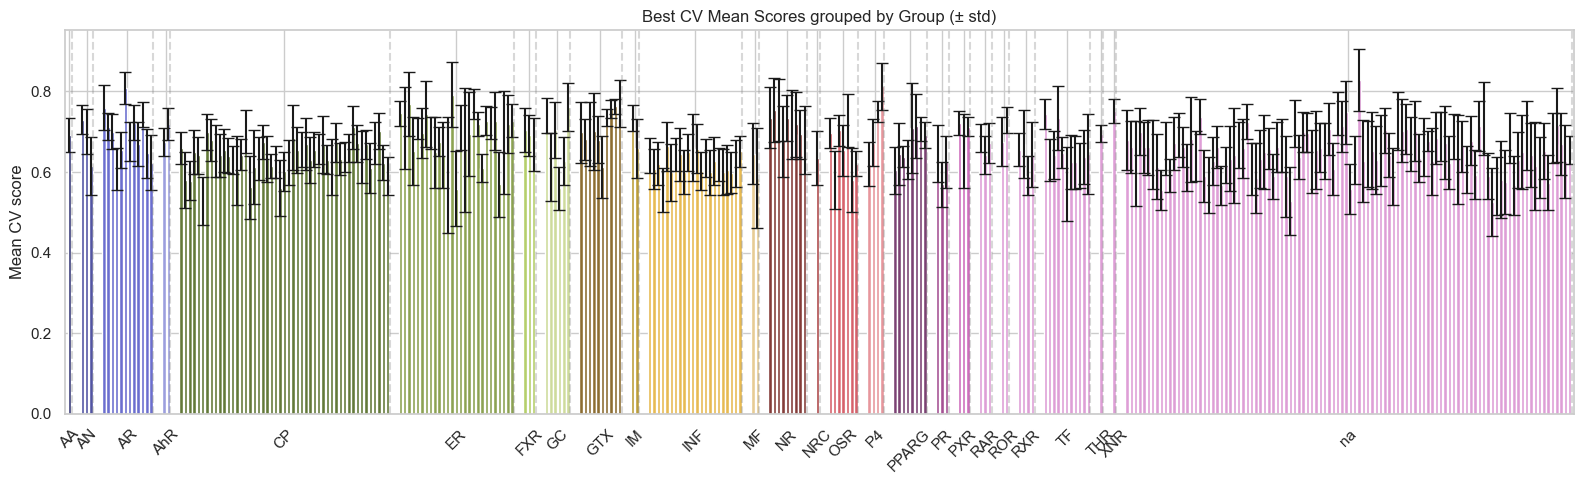

In [ ]:
import matplotlib.patches as mpatches

group_gap = 2  # increase this for more separation

x = []
pos = 0

for group, g in df_cv.groupby("group"):
    x.extend(np.arange(pos, pos + len(g)))
    pos += len(g) + group_gap

x = np.array(x)


# Map groups to colors
groups = df_cv["group"].unique()
cmap = plt.get_cmap("tab20b")
group_to_color = {g: cmap(i) for i, g in enumerate(groups)}
colors = df_cv["group"].map(group_to_color)

plt.figure(figsize=(16, 5))

plt.bar(
    x,
    df_cv["mean"],
    yerr=df_cv["std"],
    capsize=4,
    color=colors
)

plt.ylabel("Mean CV score")
plt.title("Best CV Mean Scores grouped by Group (± std)")

# Compute group label positions
group_centers = []
start = 0

for group, g in df_cv.groupby("group"):
    group_x = x[start:start + len(g)]
    group_centers.append(group_x.mean())
    start += len(g)

plt.xticks(
    group_centers,
    df_cv["group"].unique(),
    rotation = 45
)

# Optional vertical separators
start = 0
for group, g in df_cv.groupby("group"):
    end = x[start + len(g) - 1]
    plt.axvline(end + 0.5, color="gray", linestyle="--", alpha=0.3)
    start += len(g)


plt.xlim(x.min() - 1, x.max() + 1)
plt.tight_layout()

#plt.savefig("cv_scores_final_retrained.svg")
plt.show()


In [ ]:
mean =  df_cv['mean'].mean()
print(mean)
std =   df_cv['std'].mean()
print(std)

0.6591413102133559
0.06202635753347453


Compare TabPFN and final models

In [ ]:
# df_tabPFN was the results of tabpfn and df was the results of final models
df_tabPFN = pd.DataFrame(results)
df_tabPFN = df_tabPFN[df_tabPFN['group'] != 'Unknown']

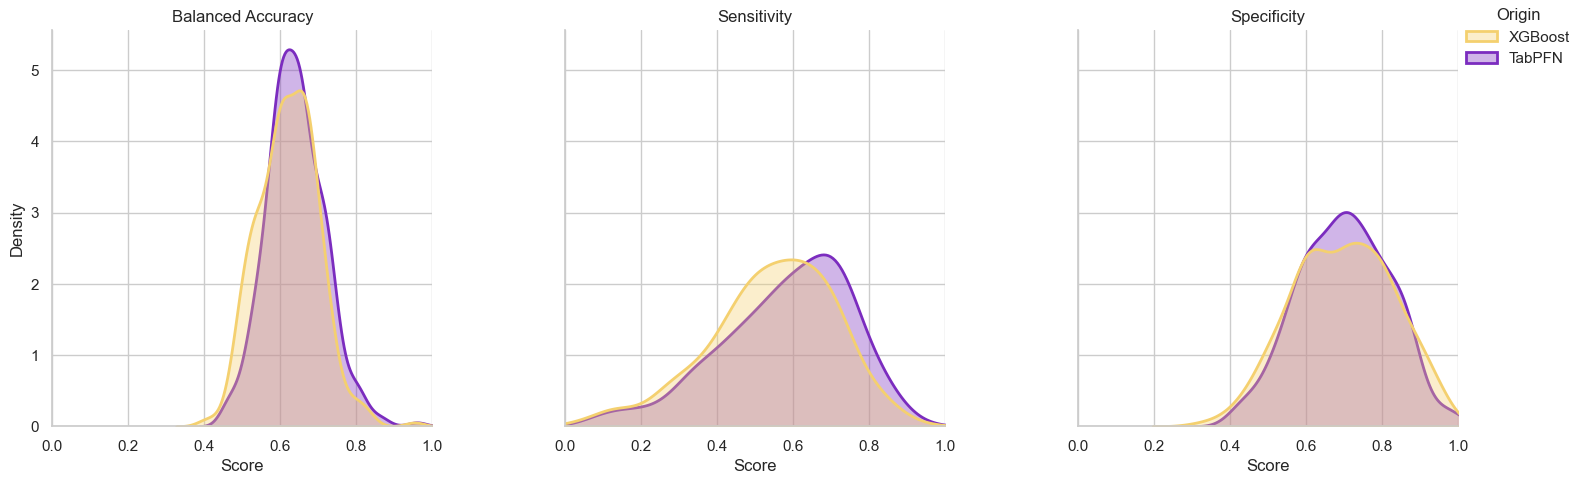

In [ ]:
# smoothed histograms, KDE. Standard Gaussian KDE doesn’t “know” about the bounds, so the smoothing leaks outside the valid range.
import matplotlib.pyplot as plt
import seaborn as sns

df1_struct = df[df["mode"] == "mb_val_structure"].copy()
df_tabPFN_struct = df_tabPFN[df_tabPFN["mode"] == "mb_val_structure"].copy()

# keep only aeids present in both
common_aeids = set(df1_struct["aeid"]) & set(df_tabPFN_struct["aeid"])

df1_struct = df1_struct[df1_struct["aeid"].isin(common_aeids)]
df_tabPFN_struct = df_tabPFN_struct[df_tabPFN_struct["aeid"].isin(common_aeids)]

df1_struct["Origin"] = 'XGBoost'
df_tabPFN_struct['Origin'] = 'TabPFN'

df_combined = pd.concat([df1_struct, df_tabPFN_struct], ignore_index=True)
df_melted = df_combined.melt(
    id_vars=['aeid', 'acr', 'Origin'],
    value_vars=['balanced_accuracy', 'Sensitivity', 'Specificity'], 
    var_name='metric',
    value_name='value'
)


# Keep only metrics of interest
df_plot = df_melted[
    df_melted['metric'].isin(['balanced_accuracy', 'Sensitivity', 'Specificity'])
].copy()

# Prettier labels
metric_labels = {
    'balanced_accuracy': 'Balanced Accuracy',
    'Sensitivity': 'Sensitivity',
    'Specificity': 'Specificity'
}
df_plot['metric'] = df_plot['metric'].map(metric_labels)

palette = {
    'XGBoost': '#f4d06f',
    'TabPFN': '#7b2cbf'
}
hue_order = list(palette.keys())

# Desired panel order
metric_order = ['Balanced Accuracy', 'Sensitivity', 'Specificity']
title_map = {
    'Balanced Accuracy': 'Balanced Accuracy',
    'Sensitivity': 'Sensitivity',
    'Specificity': 'Specificity'
}

g = sns.displot(
    data=df_plot,
    x='value',
    hue='Origin',
    col='metric',
    col_order=metric_order,
    kind='kde',
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=2,
    height=5,
    aspect=1,
    palette=palette,
    hue_order=hue_order
)

# Labels
g.set_axis_labels('Score', 'Density')
g.set(xlim=(0, 1))

for ax, metric in zip(g.axes.flat, metric_order):
    ax.set_title(title_map[metric])

# Space between panels
g.fig.subplots_adjust(wspace=0.35)

# Legend upper right
if g._legend is not None:
    g._legend.set_bbox_to_anchor((0.98, 0.98))
    g._legend._loc = 1

#plt.savefig("density_model_performance_xgboost_TabPFN.svg")
plt.show()

In [ ]:
metrics = ["balanced_accuracy", "Sensitivity", "Specificity"]

# Merge the two dataframes on aeid
comparison = (
    df1_struct[["aeid"] + metrics]
    .merge(
        df_tabPFN_struct[["aeid"] + metrics],
        on="aeid",
        suffixes=("_model1", "_model2"),
    )
)

results = {}

for metric in metrics:
    m1 = f"{metric}_model1"
    m2 = f"{metric}_model2"

    model1_wins = (comparison[m1] > comparison[m2]).sum()
    model2_wins = (comparison[m2] > comparison[m1]).sum()
    ties = (comparison[m1] == comparison[m2]).sum()

    results[metric] = {
        "XGBoost wins": model1_wins,
        "TabPFN wins": model2_wins,
        "Ties": ties,
        "Total": len(comparison),
    }

results

{'balanced_accuracy': {'XGBoost wins': np.int64(98),
  'TabPFN wins': np.int64(200),
  'Ties': np.int64(2),
  'Total': 300},
 'Sensitivity': {'XGBoost wins': np.int64(95),
  'TabPFN wins': np.int64(174),
  'Ties': np.int64(31),
  'Total': 300},
 'Specificity': {'XGBoost wins': np.int64(150),
  'TabPFN wins': np.int64(136),
  'Ties': np.int64(14),
  'Total': 300}}

Compare MLinvitroTox v2 and v3

In [ ]:
grouping_file = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\Aeid_Mech_targets.csv"
selected_aeids_df = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\selected_aeids.csv")
selected_aeids = selected_aeids_df["aeid"]

# MLinvitroTox v2
root_data_dir = r'C:\Users\aischlen\Documents\mlinvitrotox_old\data\results\models\2024-08-09_20-08-13\hitcall_c\classification'

# --- Load AEID groupings ---
group_df = pd.read_csv(grouping_file)
aeid_to_group = dict(zip(group_df['aeid'], group_df['grouped_mech_target']))
aeid_to_acr = dict(zip(group_df['aeid'], group_df['mech_target_acronym']))

# --- Data collection ---
results = []

for aeid_folder in selected_aeids:

    aeid_path = os.path.join(root_data_dir, str(aeid_folder), "Feature_Selection_RandomForestClassifier", "XGBClassifier", "mb_val_structure")
    if not os.path.isdir(aeid_path):
        continue


    metrics_file = os.path.join(aeid_path, 'metrics.csv')
    report_file = os.path.join(aeid_path, 'report_default.csv')

    if os.path.exists(metrics_file) and os.path.exists(report_file):
        metrics_df = pd.read_csv(metrics_file)
        report_df = pd.read_csv(report_file, index_col=0)

        if not metrics_df.empty:
            metrics = metrics_df.iloc[0]
        else:
            continue  # skip if no metrics

        if 'True' in report_df.index:
            precision_true = report_df.loc['True', 'precision']
            recall_true = report_df.loc['True', 'recall']
        else:
            precision_true = None
            recall_true = None

        if 'False' in report_df.index:
            recall_false = report_df.loc['False', 'recall']
        else:
            recall_false = None

        results.append({
            'aeid': int(aeid_folder),
            'group': aeid_to_group.get(int(aeid_folder), 'Unknown'),
            'acr': aeid_to_acr.get(int(aeid_folder), 'Unknown'),
            'mode': "MLinvitroTox v2",
            'f1_micro': metrics.get('f1_micro'), # chose metrics I am interested in
            'f1_macro': metrics.get('f1_macro'),
            'balanced_accuracy': metrics.get('balanced_accuracy'),
            'n_pos': metrics.get('n_pos'),
            'precision': precision_true,
            'Sensitivity': recall_true,
            'Specificity': recall_false
        })

Hyper dimensional fingerprints

In [44]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Configuration ---
root_data_dir = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\2026-07-23_17-20-46\class"
grouping_file = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\Aeid_Mech_targets.csv"

# --- Load AEID groupings ---
group_df = pd.read_csv(grouping_file)
aeid_to_group = dict(zip(group_df['aeid'], group_df['grouped_mech_target']))
aeid_to_acr = dict(zip(group_df['aeid'], group_df['mech_target_acronym']))

# --- Data collection ---
results = []

for aeid_folder in os.listdir(root_data_dir):
    if not aeid_folder.isdigit():
        continue

    aeid_path = os.path.join(root_data_dir, aeid_folder, "FS_RandomForest", "XGBClassifier")
    if not os.path.isdir(aeid_path):
        continue


    metrics_file = os.path.join(aeid_path, 'metrics.csv')
    report_file = os.path.join(aeid_path, 'report_default.csv')

    if os.path.exists(metrics_file) and os.path.exists(report_file):
        metrics_df = pd.read_csv(metrics_file)
        report_df = pd.read_csv(report_file, index_col=0)

        if not metrics_df.empty:
            metrics = metrics_df.iloc[0]
        else:
            continue  # skip if no metrics

        if 'True' in report_df.index:
            precision_true = report_df.loc['True', 'precision']
            recall_true = report_df.loc['True', 'recall']
        else:
            precision_true = None
            recall_true = None

        if 'False' in report_df.index:
            recall_false = report_df.loc['False', 'recall']
        else:
            recall_false = None

        results.append({
            'aeid': int(aeid_folder),
            'group': aeid_to_group.get(int(aeid_folder), 'Unknown'),
            'acr': aeid_to_acr.get(int(aeid_folder), 'Unknown'),
            'mode': 'HDF',
            'f1_micro': metrics.get('f1_micro'), # chose metrics I am interested in
            'f1_macro': metrics.get('f1_macro'),
            'balanced_accuracy': metrics.get('balanced_accuracy'),
            'n_pos': metrics.get('n_pos'),
            'precision': precision_true,
            'Sensitivity': recall_true,
            'Specificity': recall_false,
            'roc_auc': metrics.get('roc_auc')
        })

In [45]:
df3 = pd.DataFrame(results)
df3 = df3[df3['group'] != 'Unknown']

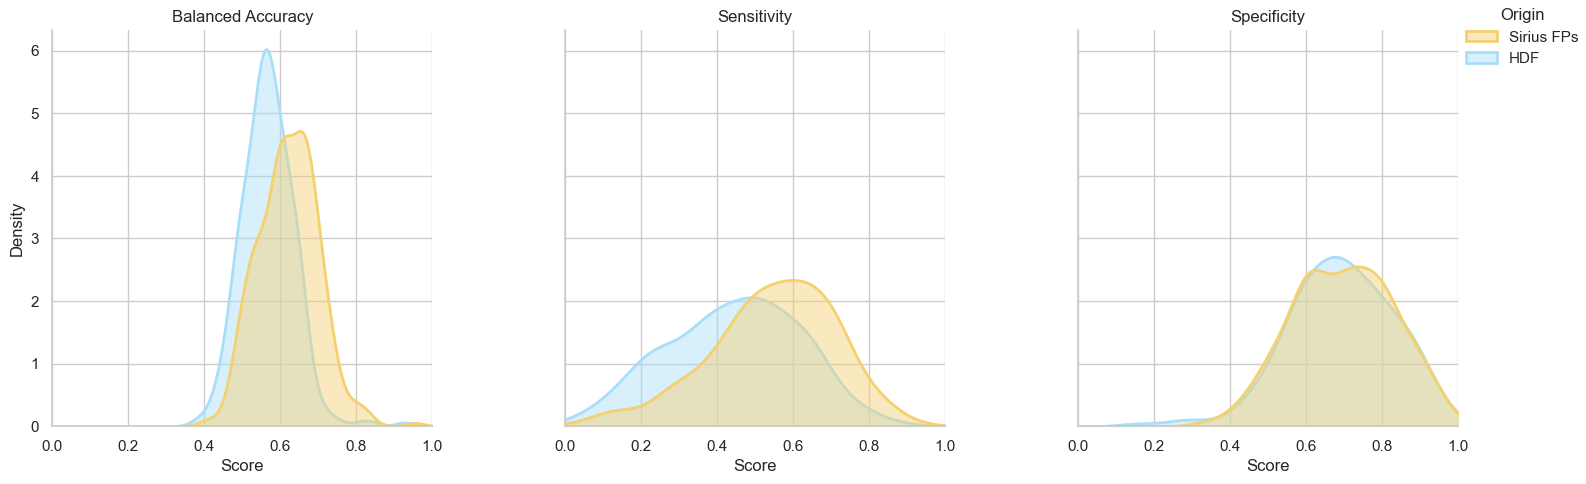

In [ ]:
# smoothed histograms, KDE. Standard Gaussian KDE doesn’t “know” about the bounds, so the smoothing leaks outside the valid range.
import matplotlib.pyplot as plt
import seaborn as sns

df1_struct = df1[df1["mode"] == "mb_val_structure"].copy()
df3_struct = df3[df3["mode"] == "HDF"].copy()

# keep only aeids present in both
common_aeids = set(df1_struct["aeid"]) & set(df3_struct["aeid"])

df1_struct = df1_struct[df1_struct["aeid"].isin(common_aeids)]
df3_struct = df3_struct[df3_struct["aeid"].isin(common_aeids)]

df1_struct["Origin"] = 'Sirius FPs'
df3_struct['Origin'] = 'HDF'

df_combined = pd.concat([df1_struct, df3_struct], ignore_index=True)
df_melted = df_combined.melt(
    id_vars=['aeid', 'acr', 'Origin'],
    value_vars=['balanced_accuracy', 'Sensitivity', 'Specificity'], 
    var_name='metric',
    value_name='value'
)


# Keep only metrics of interest
df_plot = df_melted[
    df_melted['metric'].isin(['balanced_accuracy', 'Sensitivity', 'Specificity'])
].copy()

# Prettier labels
metric_labels = {
    'balanced_accuracy': 'Balanced Accuracy',
    'Sensitivity': 'Sensitivity',
    'Specificity': 'Specificity'
}
df_plot['metric'] = df_plot['metric'].map(metric_labels)

palette = {
    'Sirius FPs': '#f4d06f',
    'HDF': '#a9def9'
}
hue_order = list(palette.keys())

# Desired panel order
metric_order = ['Balanced Accuracy', 'Sensitivity', 'Specificity']
title_map = {
    'Balanced Accuracy': 'Balanced Accuracy',
    'Sensitivity': 'Sensitivity',
    'Specificity': 'Specificity'
}

g = sns.displot(
    data=df_plot,
    x='value',
    hue='Origin',
    col='metric',
    col_order=metric_order,
    kind='kde',
    fill=True,
    common_norm=False,
    alpha=0.45,
    linewidth=2,
    height=5,
    aspect=1,
    palette=palette,
    hue_order=hue_order
)

# Labels
g.set_axis_labels('Score', 'Density')
g.set(xlim=(0, 1))

for ax, metric in zip(g.axes.flat, metric_order):
    ax.set_title(title_map[metric])

# Space between panels
g.fig.subplots_adjust(wspace=0.35)

# Legend upper right
if g._legend is not None:
    g._legend.set_bbox_to_anchor((0.98, 0.98))
    g._legend._loc = 1

#plt.savefig("density_model_performance_SiriusFPS_HDF.svg")
plt.show()